In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, Input, Dense, Flatten, MaxPooling2D, Dropout
from tensorflow.keras.utils import load_img, img_to_array

# Carregar a base de dados CIFAR-10

In [2]:
#Carregando o dataset CIFAR-10
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

#Normalizando os dados
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

# Definindo os nomes das classes do dataset CIFAR-10
class_names = [
    "avião",
    "automóvel",
    "pássaro",
    "gato",
    "cervo",
    "cachorro",
    "sapo",
    "cavalo",
    "navio",
    "caminhão"
]

print("formato de X_train:", X_train.shape)
print("formato de y_train:", y_train.shape)
print("formato de X_test:", X_test.shape)
print("formato de y_test:", y_test.shape)

formato de X_train: (50000, 32, 32, 3)
formato de y_train: (50000,)
formato de X_test: (10000, 32, 32, 3)
formato de y_test: (10000,)



# Plotar imagens

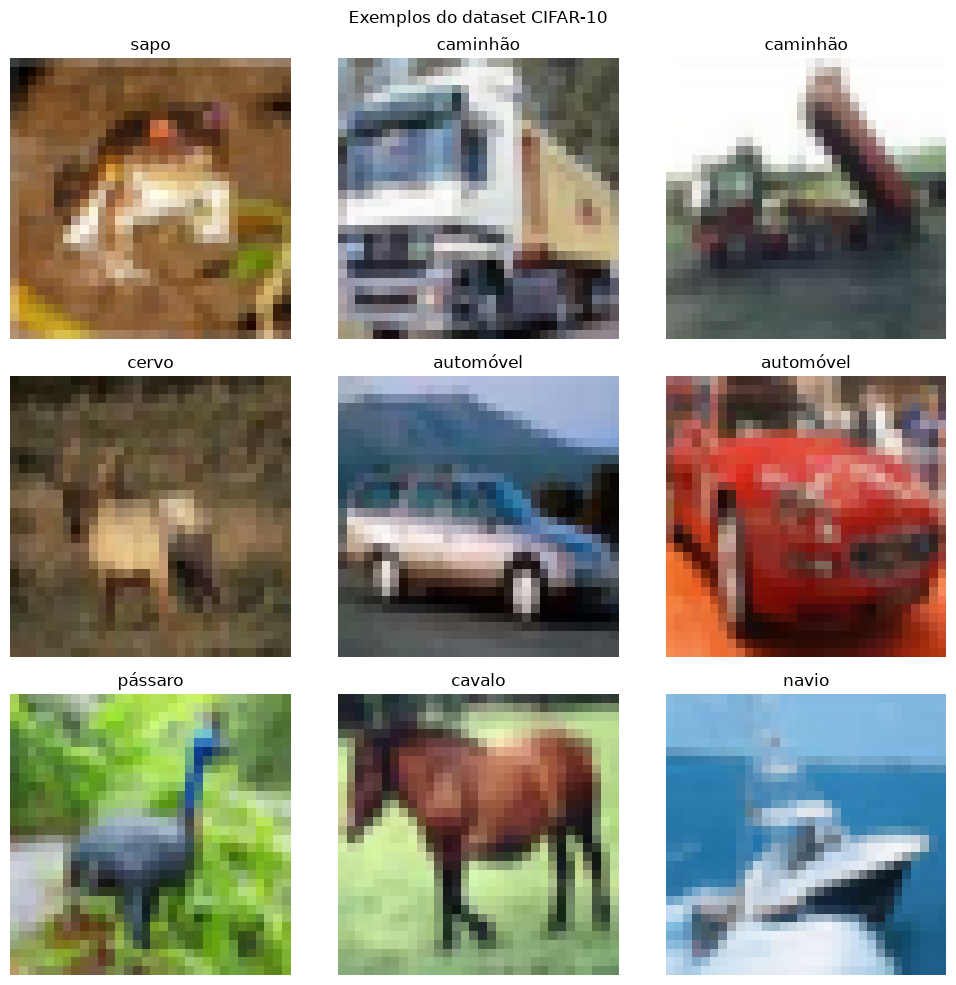

In [ ]:
plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Exemplos do dataset CIFAR-10")
plt.tight_layout()
plt.show()


# Criação do modelo CNN

In [4]:
from tensorflow.keras.layers import BatchNormalization

model = keras.Sequential()

# Adicionando a camada de entrada
model.add(Input(shape=(32, 32, 3)))

# Adicionando a primeira camada convolucional
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

# Adicionando a primeira camada de pooling
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.25))  # Adicionando uma camada de dropout para reduzir overfitting


# Adicionando a segunda camada convolucional
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

# Adicionando a segunda camada de pooling
model.add(MaxPooling2D((2, 2)))

model.add(Dropout(0.25))  # Adicionando uma camada de dropout para reduzir overfitting


# Adicionando a terceira camada convolucional
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())

# Adicionando a terceira camada de pooling
model.add(MaxPooling2D((2, 2)))

model.add(Dropout(0.25))  # Adicionando uma camada de dropout para reduzir overfitting


# Transição CNN -> Dense (totalmente conectada)
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))  # Adicionando uma camada de dropout para reduzir overfitting
model.add(Dense(10, activation='softmax'))


#Compiler
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

# Resumo da arquitetura do modelo
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           65

 Total params: 420,586 (1.60 MB)

 Trainable params: 419,690 (1.60 MB)

 Non-trainable params: 896 (3.50 KB)

# Treinar a rede

In [6]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


history = model.fit(X_train, y_train, epochs=30, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 65s 50ms/step - accuracy: 0.2682 - loss: 1.9004 - val_accuracy: 0.4369 - val_loss: 1.5333
Epoch 2/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 54s 43ms/step - accuracy: 0.3724 - loss: 1.6381 - val_accuracy: 0.5074 - val_loss: 1.3720
Epoch 3/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 46ms/step - accuracy: 0.4646 - loss: 1.4212 - val_accuracy: 0.5565 - val_loss: 1.2512
Epoch 4/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 60s 48ms/step - accuracy: 0.5399 - loss: 1.2655 - val_accuracy: 0.6623 - val_loss: 0.9631
Epoch 5/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 60s 48ms/step - accuracy: 0.5909 - loss: 1.1486 - val_accuracy: 0.6931 - val_loss: 0.9113
Epoch 6/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 46ms/step - accuracy: 0.6406 - loss: 1.0332 - val_accuracy: 0.7244 - val_loss: 0.8444
Epoch 7/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 58s 46ms/step - accuracy: 0.6757 - loss: 0.9469 - val_accuracy: 0.7301 - val_loss: 0.8386
Epoch 8/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 55ms/step - accuracy: 0.7010 -

# Plot da acurária x loss

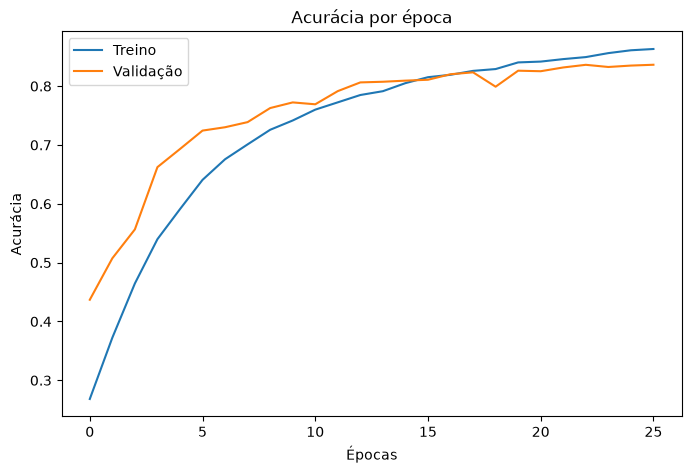

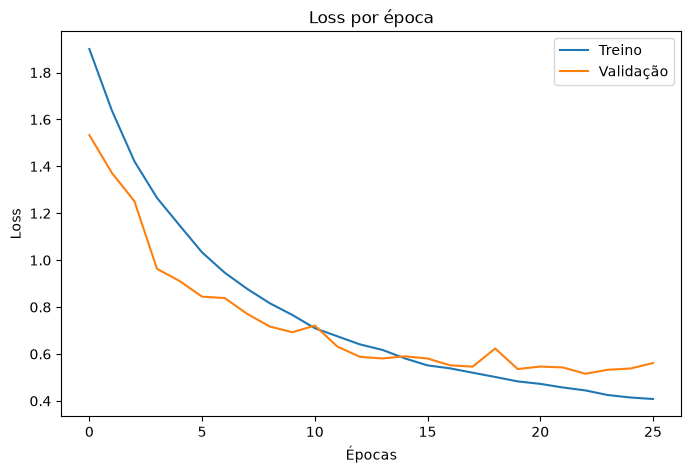

In [7]:

# Plotting Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title("Acurácia por época")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.show()


# Plotting Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title("Loss por época")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Realizando predições

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8275 - loss: 0.5554
Test Loss: 0.5554
Test Accuracy: 82.75%


# Previsões em imagens testes

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step


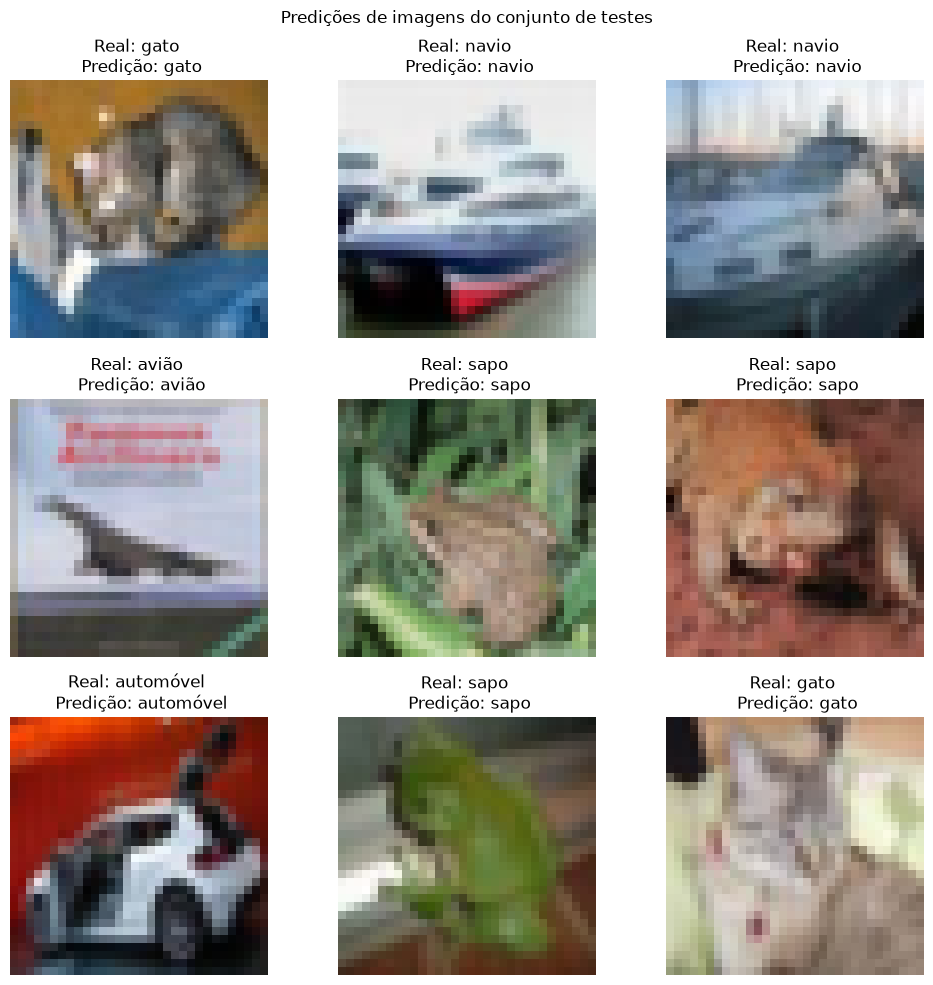

In [9]:
pred_probs = model.predict(X_test[:9])

pred_labels = np.argmax(pred_probs, axis=1)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    real = class_names[y_test[i]]
    pred = class_names[pred_labels[i]]
    plt.title(f"Real: {real} \n Predição: {pred}")
    plt.axis("off")
plt.suptitle("Predições de imagens do conjunto de testes")
plt.tight_layout()
plt.show()

# Matriz de confusão

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


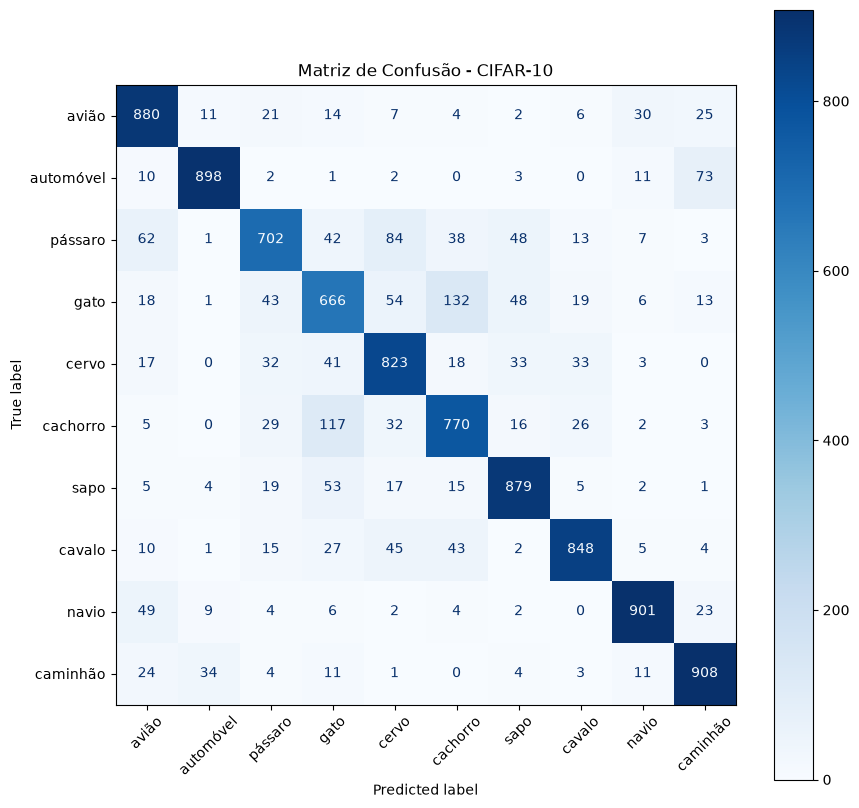

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred_probs = model.predict(X_test)
pred_labels = np.argmax(pred_probs, axis=1)

cm = confusion_matrix(y_test, pred_labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)

plt.title("Matriz de Confusão - CIFAR-10")
plt.show()